# Ovarian tumor cohort (2/4): capture and enrichment within each donor (Supplementary Fig. S9)

The donor is an input of the decoder for $\pi$, so a variant confined to one donor could look enriched and be captured through the donor alone. Here enrichment and capture are recomputed within each donor (Methods): the non-mutant cells are those of the same donor, and the neighbor graph is built on the covered cells of that donor with $z$ standardized within the donor ($K = 30$, 500 permutations).

The analysis was fixed before its numbers were seen. Its other quantities (bootstrap intervals of the AUC, the AUC of the test cells, enrichment for other $K$, the AUC after permuting the labels) are computed as planned, in the same order of random draws; the figure uses the enrichment ($K = 30$) and the AUC.

- Fit: `output/v2/ovarian_bkg/202610/11/080711` (see `04a_ovarian.ipynb`). Output: `analysis/results/ovarian/`. Runs for about 15 minutes.

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os
import hashlib

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.stats import rankdata, spearmanr
from sklearn.neighbors import NearestNeighbors

In [3]:
RUN = '../output/v2/ovarian_bkg/202610/11/080711'
OUT = '../analysis/results/ovarian'
os.makedirs(OUT, exist_ok=True)
K_MAIN, K_SENS = 30, (10, 50, 100)
NPERM, NBOOT, MIN_GROUP, SEED = 500, 2000, 15, 0

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
RASTER = False
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

## 1. The data

In [6]:
adata_mg = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')
test_mg = sc.read_h5ad(f'{RUN}/cloneVI_test_result.h5ad')
D = den(adata_mg.X).astype(float)
V = den(adata_mg.layers['VAF']).astype(float)
A = den(adata_mg.layers['all_mut']).astype(float)
P = np.asarray(adata_mg.obsm['pi_deleted']) @ np.asarray(adata_mg.varm['phi_deleted']).T     # reconstruction from the kept clones
Z = np.asarray(adata_mg.obsm['z'])
donor = adata_mg.obs['donor'].to_numpy()
DONORS = list(pd.unique(donor))
variants = list(adata_mg.var_names)
phi_kept = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)
phi_common = np.asarray(adata_mg.varm['phi_0'], dtype=float).mean(1)
pi_all = np.asarray(adata_mg.obsm['pi_sorted'])
kept = np.flatnonzero((pi_all.mean(0) > 0.01) | (pi_all.max(0) >= 0.2))
K12 = int(kept[(phi_kept - phi_common[:, None])[variants.index('12879T>C')].argmax()])   # the clone of 12879T>C (Clone 11)
test = np.asarray(adata_mg.obs_names.isin(test_mg.obs_names))
pd.Series({'cells': adata_mg.n_obs, 'variants': len(variants), 'donors': len(DONORS), 'test cells': int(test.sum())})

cells         108260
variants          64
donors             5
test cells     10826
dtype: int64

## 2. Enrichment and AUC for every variant in every donor

A (variant, donor) pair is analyzed if the donor has at least 15 mutant and 15 non-mutant covered cells (mutant: VAF at least 0.10 with at least three alternate reads, depth at least 10).

In [7]:
def auc_from_scores(score, is_mut):
    # AUC with ties at one half, from ranks
    n_pos, n_neg = int(is_mut.sum()), int((~is_mut).sum())
    r = rankdata(score, method='average')
    return float((r[is_mut].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def auc_ci(score, is_mut, rng):
    # two-sample bootstrap within the donor
    pos, neg = score[is_mut], score[~is_mut]
    out = np.empty(NBOOT)
    for b in range(NBOOT):
        p, n = rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)
        out[b] = auc_from_scores(np.concatenate([p, n]), np.r_[np.ones(len(p), bool), np.zeros(len(n), bool)])
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))


def local_gain(zd, is_mut, cache, key, rng):
    # enrichment among the covered cells of one donor, for each K
    if key not in cache:
        k_max = min(max(K_MAIN, *K_SENS), len(zd) - 1)
        cache[key] = NearestNeighbors(n_neighbors=k_max + 1).fit(zd).kneighbors(zd, return_distance=False)[:, 1:]
    nb = cache[key]
    car, pool, out = np.flatnonzero(is_mut), np.arange(len(is_mut)), {}
    for K in (K_MAIN,) + K_SENS:
        if K > nb.shape[1]:
            out[K] = np.nan
            continue
        purity = is_mut[nb[car, :K]].mean()
        null = np.empty(NPERM)
        for b in range(NPERM):
            perm = np.zeros(len(is_mut), bool)
            perm[rng.choice(pool, len(car), replace=False)] = True
            null[b] = perm[nb[np.flatnonzero(perm), :K]].mean()
        out[K] = float((purity - null.mean()) / (1 - null.mean()))
        if K == K_MAIN:
            out['purity'], out['null_mean'] = float(purity), float(null.mean())
    return out

In [8]:
rng = np.random.default_rng(SEED)
cache, rows = {}, []
for j, v in enumerate(variants):
    covered_all = D[:, j] >= 10
    mutant_all = covered_all & (V[:, j] >= 0.10) & (A[:, j] >= 3)
    for d in DONORS:
        covered, mutant = covered_all & (donor == d), mutant_all & (donor == d)
        n_mut, n_non = int(mutant.sum()), int((covered & ~mutant).sum())
        if n_mut < MIN_GROUP or n_non < MIN_GROUP:
            continue
        idx = np.flatnonzero(covered)
        is_mut, score = mutant[idx], P[idx, j]
        auc = auc_from_scores(score, is_mut)
        lo, hi = auc_ci(score, is_mut, rng)
        zd = Z[idx]
        zd = (zd - zd.mean(0)) / np.maximum(zd.std(0), 1e-9)                # standardized within the donor
        g = local_gain(zd, is_mut, cache, (d, hashlib.md5(covered.tobytes()).hexdigest()), rng)
        te = test[idx]
        auc_te = (auc_from_scores(score[te], is_mut[te]) if is_mut[te].sum() >= MIN_GROUP and (~is_mut[te]).sum() >= MIN_GROUP
                  else np.nan)
        rows.append(dict(variant=v, donor=d, n_mutant=n_mut, n_nonmutant=n_non, auc=auc, auc_lo=lo, auc_hi=hi,
                         auc_permuted=auc_from_scores(score, rng.permutation(is_mut)), auc_test_cells=auc_te,
                         enrichment=g[K_MAIN], purity=g['purity'], null_purity=g['null_mean'],
                         **{f'enrichment_K{K}': g[K] for K in K_SENS},
                         heteroplasmy=float(V[idx[is_mut], j].mean()), prevalence=float(np.log10(n_mut))))
wd = pd.DataFrame(rows)
wd.to_csv(f'{OUT}/supfig9_within_donor.csv', index=False)
len(wd), wd.groupby('donor').size().to_dict()

(94,
 {'SU-O-001': 18,
  'SU-O-002': 25,
  'SU-O-003': 5,
  'SU-O-004': 22,
  'SU-O-005': 24})

In [9]:
wd.sort_values(['donor', 'enrichment'], ascending=[True, False]).round(3)

,variant,donor,n_mutant,n_nonmutant,auc,auc_lo,auc_hi,auc_permuted,auc_test_cells,enrichment,purity,null_purity,enrichment_K10,enrichment_K50,enrichment_K100,heteroplasmy,prevalence
86,14386T>C,SU-O-001,930,7367,0.943,0.932,0.954,0.509,0.925,0.815,0.835,0.112,0.817,0.813,0.811,0.837,2.968
60,8134T>C,SU-O-001,164,8090,0.891,0.875,0.905,0.505,0.871,0.408,0.420,0.020,0.485,0.359,0.285,0.295,2.215
16,709G>A,SU-O-001,1871,6342,0.779,0.766,0.792,0.495,0.738,0.381,0.522,0.228,0.394,0.376,0.370,0.872,3.272
79,12341C>T,SU-O-001,488,7598,0.814,0.790,0.837,0.519,0.757,0.267,0.311,0.060,0.302,0.250,0.224,0.882,2.688
3,195T>C,SU-O-001,166,6339,0.794,0.757,0.829,0.550,NaN,0.213,0.233,0.026,0.256,0.191,0.153,0.849,2.220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,14488T>C,SU-O-005,26,26241,0.467,0.362,0.577,0.513,NaN,-0.001,0.000,0.001,-0.001,-0.001,-0.001,0.178,1.415
32,2514C>A,SU-O-005,42,31494,0.504,0.424,0.587,0.477,NaN,-0.001,0.000,0.001,-0.001,-0.001,-0.001,0.149,1.623
54,4837C>A,SU-O-005,51,28204,0.563,0.484,0.644,0.481,NaN,-0.002,0.000,0.002,-0.002,-0.002,-0.001,0.158,1.708
44,3244G>A,SU-O-005,64,30222,0.602,0.546,0.661,0.536,NaN,-0.002,0.000,0.002,-0.002,-0.001,-0.001,0.435,1.806


## 3. Spearman correlation of enrichment and AUC in each donor

In [10]:
per_donor = wd.groupby('donor').apply(lambda g: pd.Series({'variants': len(g), 'rho': spearmanr(g['enrichment'], g['auc'])[0]}))
per_donor.to_csv(f'{OUT}/supfig9_rho_by_donor.csv')
per_donor.round(3), round(wd['auc_permuted'].mean(), 4)

/tmp/ipykernel_1000457/2637677655.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_donor = wd.groupby('donor').apply(lambda g: pd.Series({'variants': len(g), 'rho': spearmanr(g['enrichment'], g['auc'])[0]}))


(          variants    rho
 donor                    
 SU-O-001      18.0  0.684
 SU-O-002      25.0  0.660
 SU-O-003       5.0  0.100
 SU-O-004      22.0  0.647
 SU-O-005      24.0  0.556,
 0.4969)

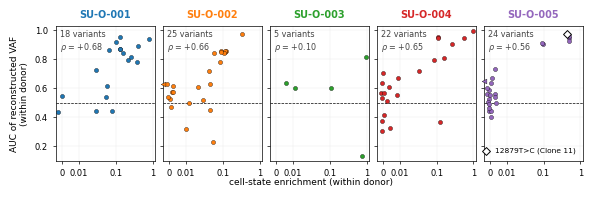

In [11]:
DS = sorted(wd['donor'].unique())
dcol = dict(zip(DS, plt.get_cmap('tab10')(np.arange(len(DS)))))
XMIN = -0.004                       # left limit of the enrichment axis; points beyond it are drawn at the edge
YMIN = min(0.2, np.floor(wd['auc'].min() * 10) / 10)   # lower limit of the AUC axis, below the lowest AUC (1348G>A in SU-O-003)
fig, axes = plt.subplots(1, len(DS), figsize=(6.8, 1.75), sharex=True, sharey=True, gridspec_kw={'wspace': 0.08})
for ax, d in zip(axes, DS):
    g = wd[wd['donor'] == d]
    ex = g['variant'] == '12879T>C'
    out = g['enrichment'] < XMIN
    main = ~ex & ~out
    ax.scatter(g['enrichment'][main], g['auc'][main], s=9, color=dcol[d], edgecolor='k', lw=0.25, zorder=3)
    if out.any():
        ax.scatter(np.full(out.sum(), XMIN * 0.9), g['auc'][out], marker='<', s=12, color=dcol[d], edgecolor='k', lw=0.25,
                   zorder=3, clip_on=False)
    if ex.any():
        ax.scatter(g['enrichment'][ex], g['auc'][ex], marker='D', s=16, c='white', edgecolor='k', lw=0.7, zorder=4,
                   label=f'12879T>C (Clone {K12})')
        ax.legend(loc='lower right', frameon=False, fontsize=5.4, handletextpad=0.2)
    ax.axhline(0.5, color='k', lw=0.5, ls='--', zorder=1)
    ax.text(0.04, 0.97, f'{len(g)} variants\n$\\rho$ = {per_donor.loc[d, "rho"]:+.2f}', transform=ax.transAxes, ha='left',
            va='top', fontsize=5.8, color='#444')
    ax.set_title(d, color=dcol[d], fontweight='bold')
    ax.grid(alpha=0.25, lw=0.3)
axes[0].set_xscale('symlog', linthresh=0.01, linscale=0.4)
axes[0].set_xticks([0, 0.01, 0.1, 1]); axes[0].set_xticklabels(['0', '0.01', '0.1', '1'])
axes[0].set_xlim(XMIN, 1.15)
axes[0].set_ylim(YMIN, 1.03)
axes[0].set_ylabel('AUC of reconstructed VAF\n(within donor)')
fig.supxlabel('cell-state enrichment (within donor)', fontsize=6.5, y=-0.04)
save(fig, 'supfig9_within_donor')

## 4. The numbers in the paper

`where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [12]:
r310 = wd[(wd['variant'] == '310T>C') & (wd['donor'] == 'SU-O-005')]['enrichment'].iloc[0]
a1348 = wd[(wd['variant'] == '1348G>A') & (wd['donor'] == 'SU-O-003')]['auc'].iloc[0]
R, S9 = 'Results (ovarian cohort)', 'Supp. Fig. S9 legend'
rows = [('within-donor rho, range', f'{R}; {S9}', '+0.10 to +0.68',
         f'{per_donor["rho"].min():+.2f} to {per_donor["rho"].max():+.2f}'),
        ('positive in every donor', R, 'yes', 'yes' if (per_donor['rho'] > 0).all() else 'no'),
        ('variants in SU-O-003', S9, '5', str(int(per_donor.loc['SU-O-003', 'variants']))),
        ('rho in SU-O-003', S9, '+0.10', f"{per_donor.loc['SU-O-003', 'rho']:+.2f}"),
        ('AUC of 1348G>A within SU-O-003', S9, '0.13', f'{a1348:.2f}'),
        ('enrichment of 310T>C in SU-O-005', S9, '-0.03', f'{r310:+.2f}'),
        ('permutations', 'Methods (Within-donor analysis of the ovarian cohort)', '500', str(NPERM))]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.to_csv(f'{OUT}/numbers_04b.csv', index=False)
numbers

,item,where,paper,computed,match
0,"within-donor rho, range",Results (ovarian cohort); Supp. Fig. S9 legend,+0.10 to +0.68,+0.10 to +0.68,True
1,positive in every donor,Results (ovarian cohort),yes,yes,True
2,variants in SU-O-003,Supp. Fig. S9 legend,5,5,True
3,rho in SU-O-003,Supp. Fig. S9 legend,+0.10,+0.10,True
4,AUC of 1348G>A within SU-O-003,Supp. Fig. S9 legend,0.13,0.13,True
5,enrichment of 310T>C in SU-O-005,Supp. Fig. S9 legend,-0.03,-0.03,True
6,permutations,Methods (Within-donor analysis of the ovarian ...,500,500,True


## 5. Supplementary Fig. S9 as a figure

The panel of section 3 at the text width, with the sizes shared by all figures (as in `03e_cll_figure4.ipynb`): five square plots that share the y axis, and the x label below them all.

In [13]:
# sizes shared by all figures (points), as in 03e_cll_figure4.ipynb
W = 505.69                          # text width
M = 1                               # outer margin
MB = 4                              # bottom margin
CL = 3                              # clearance at the right of a panel
T = 11                              # title row above a panel; titles stand on its baseline
PAD = 3                             # baseline of the titles above the axes
plt.rcParams['axes.titlepad'] = PAD

figure 505.69 x 129.0 pt; plots 88.5 pt


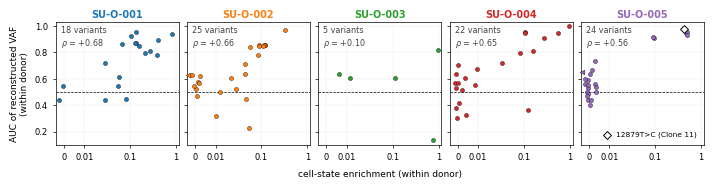

In [14]:
DS = sorted(wd['donor'].unique())
dcol = dict(zip(DS, plt.get_cmap('tab10')(np.arange(len(DS)))))
XMIN = -0.004
YMIN = min(0.2, np.floor(wd['auc'].min() * 10) / 10)   # below the lowest AUC (1348G>A in SU-O-003)
L2 = 34                                              # the two-line y label and the tick labels
G9 = 6                                               # gap between the plots (they share the y axis)
PW = (W - 2 * M - L2 - (len(DS) - 1) * G9 - CL) / len(DS)   # square plots across the text width
BX = 2 + 3.5 + 1.2 * 6 + 4 + 1.2 * 6.5               # below: ticks, tick labels and the x label
H = M + T + PW + BX + MB
fig = plt.figure(figsize=(W / 72, H / 72))
axes = lambda x, y, w, h: fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
axs = [axes(M + L2 + i * (PW + G9), M + T, PW, PW) for i in range(len(DS))]
for ax, d in zip(axs, DS):
    g = wd[wd['donor'] == d]
    ex = g['variant'] == '12879T>C'
    out = g['enrichment'] < XMIN
    main = ~ex & ~out
    ax.scatter(g['enrichment'][main], g['auc'][main], s=9, color=dcol[d], edgecolor='k', lw=0.25, zorder=3)
    if out.any():
        ax.scatter(np.full(out.sum(), XMIN * 0.9), g['auc'][out], marker='<', s=12, color=dcol[d], edgecolor='k', lw=0.25,
                   zorder=3, clip_on=False)
    if ex.any():
        ax.scatter(g['enrichment'][ex], g['auc'][ex], marker='D', s=16, c='white', edgecolor='k', lw=0.7, zorder=4,
                   label=f'12879T>C (Clone {K12})')
        ax.legend(loc='lower right', frameon=False, fontsize=5.4, handletextpad=0.2)
    ax.axhline(0.5, color='k', lw=0.5, ls='--', zorder=1)
    ax.text(0.04, 0.97, f'{len(g)} variants\n$\\rho$ = {per_donor.loc[d, "rho"]:+.2f}', transform=ax.transAxes, ha='left',
            va='top', fontsize=5.8, color='#444')
    ax.set_title(d, color=dcol[d], fontweight='bold')
    ax.grid(alpha=0.25, lw=0.3)
    ax.set_xscale('symlog', linthresh=0.01, linscale=0.4)
    ax.set_xticks([0, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
    ax.set_xlim(XMIN, 1.15)
    ax.set_ylim(YMIN, 1.03)
    if ax is not axs[0]:
        ax.tick_params(labelleft=False)
axs[0].set_ylabel('AUC of reconstructed VAF\n(within donor)')
x0, x1 = M + L2, M + L2 + len(DS) * PW + (len(DS) - 1) * G9
fig.text((x0 + x1) / 2 / W, MB / H, 'cell-state enrichment (within donor)', ha='center', va='bottom',
         fontsize=plt.rcParams['axes.labelsize'])
fig.savefig(f'{OUT}/supfig9.pdf')
fig.savefig(f'{OUT}/supfig9.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; plots {PW:.1f} pt')